# Predicción de la duración de viajes en taxi de Nueva York con PySpark y MLlib
Carlos Martínez Vázquez (A01711730)

Objetivo: Poder procesar millones de viajes de taxi, entrenar un modelo de regresión que estime cuánto va a durar un viaje antes de que empiece, evaluarlo y preparar los datos de un tablero que apoye la toma de decisiones.

Datos: NYC TLC Trip Record Data, viajes de taxis amarillos de enero a abril de 2025 (https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).

Ambiente: lo corrí en mi máquina con PySpark en modo local (10 núcleos y 16 GB de RAM), no en Colab.

## Paso 1: Configuración del ambiente

In [1]:
# Spark 4 necesita Java 17 o 21. Se ignora el SPARK_HOME del clúster para usar el pyspark del .venv.
import os, sys, glob, time, tempfile, urllib.request
from pathlib import Path
jdks = glob.glob("/opt/homebrew/opt/openjdk@21/libexec/openjdk.jdk/Contents/Home") + \
       glob.glob("/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home")
if jdks:
    os.environ["JAVA_HOME"] = jdks[0]
os.environ.pop("SPARK_HOME", None)
os.environ["PYSPARK_PYTHON"] = sys.executable

import pandas as pd
import matplotlib.pyplot as plt
from pyspark import StorageLevel
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("Taxi_Duracion_MLlib") \
    .config("spark.driver.memory", "10g") \
    .config("spark.sql.shuffle.partitions", "64") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir(tempfile.mkdtemp())
print(f"PySpark {spark.version} | Master: {spark.sparkContext.master}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
.../site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/22 18:22:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


PySpark 4.3.0 | Master: local[*]


In [2]:
MESES = ["2025-01", "2025-02", "2025-03", "2025-04"]
DATA_DIR = Path("data/taxi")
TABLERO_DIR = DATA_DIR / "tablero"
MODELO_DIR = "models/taxi_gbt_pipeline"
RUTAS_DIR = "models/taxi_distancia_ruta"
SEED = 42
FRACCION_TUNING = 0.05    # parte de entrenamiento para buscar hiperparámetros
FRACCION_GBT = 1.0       # parte de entrenamiento para el modelo final de árboles

## Paso 2: Extracción
Descargo los archivos solo si no los tengo. Vienen en Parquet, un formato por columnas, así que Spark lee únicamente las columnas que necesito.

In [3]:
BASE = "https://d37ci6vzurychx.cloudfront.net"
DATA_DIR.mkdir(parents=True, exist_ok=True)
for ruta, url in [(DATA_DIR / f"yellow_tripdata_{m}.parquet", f"{BASE}/trip-data/yellow_tripdata_{m}.parquet") for m in MESES] + \
                 [(DATA_DIR / "taxi_zone_lookup.csv", f"{BASE}/misc/taxi_zone_lookup.csv")]:
    if not ruta.exists():
        urllib.request.urlretrieve(url, ruta)

crudos = spark.read.parquet(*[str(DATA_DIR / f"yellow_tripdata_{m}.parquet") for m in MESES])
zonas = spark.read.csv(str(DATA_DIR / "taxi_zone_lookup.csv"), header=True, inferSchema=True)

n_crudos = crudos.count()
crudos.printSchema()
print(f"Registros: {n_crudos:,} | Columnas: {len(crudos.columns)} | Particiones: {crudos.rdd.getNumPartitions()}")
zonas.where("LocationID >= 263").show(truncate=False)

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)

Registros: 15,168,579 | Columnas: 20 | Particiones: 11


+----------+---------+--------------+------------+
|LocationID|Borough  |Zone          |service_zone|
+----------+---------+--------------+------------+
|263       |Manhattan|Yorkville West|Yellow Zone |
|264       |Unknown  |N/A           |N/A         |
|265       |N/A      |Outside of NYC|N/A         |
+----------+---------+--------------+------------+



## Paso 3: Limpieza
Los datos traen errores: duraciones negativas, viajes de otros años, distancias imposibles y tarifas negativas. A cada viaje le asigno un motivo de exclusión, o nulo si es válido, para que quede registrado qué quité y por qué. Las reglas son:

1. Fecha de inicio fuera de enero a abril de 2025.
2. Duración menor a 1 minuto o mayor a 3 horas.
3. Distancia en cero o mayor a 100 millas.
4. Tarifa en cero o negativa (cancelaciones y reembolsos).
5. Zona desconocida o fuera de Nueva York (264 y 265).
6. Velocidad promedio mayor a 80 millas por hora.

Al final también quito los registros duplicados.

In [4]:
t0 = time.time()
base = (crudos
    .withColumn("duracion_min", (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60)
    .withColumn("velocidad_mph", F.col("trip_distance") / (F.col("duracion_min") / 60)))

clasificados = base.withColumn("motivo_exclusion",
    F.when((F.col("tpep_pickup_datetime") < "2025-01-01") | (F.col("tpep_pickup_datetime") >= "2025-05-01"), "fecha_fuera_de_periodo")
     .when((F.col("duracion_min") < 1) | (F.col("duracion_min") > 180), "duracion_invalida")
     .when((F.col("trip_distance") <= 0) | (F.col("trip_distance") > 100), "distancia_invalida")
     .when(F.col("fare_amount") <= 0, "tarifa_invalida")
     .when(F.col("PULocationID").isin(264, 265) | F.col("DOLocationID").isin(264, 265), "zona_desconocida")
     .when(F.col("velocidad_mph") > 80, "velocidad_imposible"))

reporte = clasificados.groupBy(F.coalesce("motivo_exclusion", F.lit("valido")).alias("estado")).count() \
                      .withColumn("pct", F.round(F.col("count") / n_crudos * 100, 2)).orderBy(F.desc("count"))
reporte.show(truncate=False)

viajes = (clasificados.where(F.col("motivo_exclusion").isNull())
    .dropDuplicates(["VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance", "total_amount"])
    .withColumn("mes", F.month("tpep_pickup_datetime"))
    .withColumn("hora", F.hour("tpep_pickup_datetime"))
    .withColumn("dia_semana", F.dayofweek("tpep_pickup_datetime"))   # 1 = domingo, 7 = sábado
    .withColumn("fin_de_semana", F.col("dia_semana").isin(1, 7).cast("int"))
    .select("PULocationID", "DOLocationID", "mes", "hora", "dia_semana", "fin_de_semana",
            "duracion_min", "trip_distance", "velocidad_mph", "total_amount")
    .persist(StorageLevel.MEMORY_AND_DISK))

n_viajes = viajes.count()
print(f"Viajes limpios: {n_viajes:,} ({n_viajes / n_crudos:.1%} de los originales) | {time.time() - t0:.0f} s")
viajes.select("duracion_min", "trip_distance", "velocidad_mph").summary("min", "25%", "50%", "75%", "max", "mean").show()

+----------------------+--------+-----+
|estado                |count   |pct  |
+----------------------+--------+-----+
|valido                |13913198|91.72|
|tarifa_invalida       |650918  |4.29 |
|distancia_invalida    |275870  |1.82 |
|duracion_invalida     |230567  |1.52 |
|zona_desconocida      |97313   |0.64 |
|velocidad_imposible   |687     |0.0  |
|fecha_fuera_de_periodo|26      |0.0  |
+----------------------+--------+-----+



Viajes limpios: 13,913,198 (91.7% de los originales) | 8 s


+-------+------------------+------------------+--------------------+
|summary|      duracion_min|     trip_distance|       velocidad_mph|
+-------+------------------+------------------+--------------------+
|    min|               1.0|              0.01|0.004090444267696852|
|    25%| 7.733333333333333|              1.06|   7.283236994219653|
|    50%|12.333333333333334|              1.78|   9.559074299634592|
|    75%|             19.25|              3.31|  12.947705442902882|
|    max|179.96666666666667|              90.2|   79.96120271580988|
|   mean|15.459534183538073|3.2100820321827097|  11.116495701143554|
+-------+------------------+------------------+--------------------+



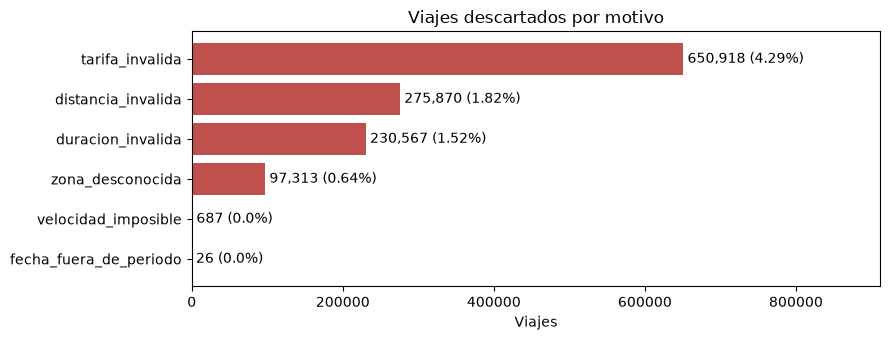

In [5]:
# Pasar a pandas solo tablas chicas ya agregadas por Spark
a_pandas = lambda df: pd.DataFrame([r.asDict() for r in df.collect()])

excluidos = a_pandas(reporte.where("estado != 'valido'")).sort_values("count")
fig, ax = plt.subplots(figsize=(9, 3.5))
barras = ax.barh(excluidos["estado"], excluidos["count"], color="#c0504d")
ax.bar_label(barras, labels=[f"{c:,} ({p}%)" for c, p in zip(excluidos["count"], excluidos["pct"])], padding=3)
ax.set(title="Viajes descartados por motivo", xlabel="Viajes")
ax.set_xlim(0, excluidos["count"].max() * 1.4)
plt.tight_layout(); plt.show()

Observación: lo que más quité fueron tarifas en cero o negativas (4.29%), que son cancelaciones y reembolsos. Después vienen distancias y duraciones imposibles. Las velocidades imposibles y las fechas fuera de periodo casi no aparecen. En total descarté 8.3% de los viajes, así que los datos limpios siguen representando casi todo el periodo.

## Paso 4: Análisis exploratorio
Antes de modelar reviso cómo se comportan los viajes limpios. Spark hace las agregaciones sobre los 13.9 millones de viajes y a pandas solo paso tablas chicas, o una muestra pequeña para las gráficas de dispersión. Así el driver no tiene que cargar millones de filas en memoria.

### Duración de los viajes
Es la variable que quiero predecir.

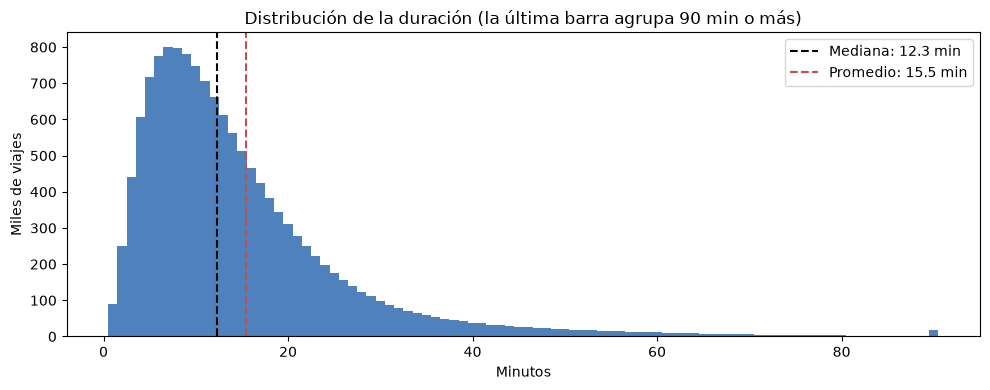

Viajes de más de una hora: 1.21%


In [6]:
dur = a_pandas(viajes.groupBy(F.least(F.floor("duracion_min"), F.lit(90)).alias("minuto")).count().orderBy("minuto"))
stats = viajes.agg(F.avg("duracion_min").alias("prom"), F.percentile_approx("duracion_min", 0.5).alias("mediana"),
                   F.avg((F.col("duracion_min") > 60).cast("int")).alias("mas_1h")).first()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(dur["minuto"], dur["count"] / 1000, width=1, color="#4f81bd")
ax.axvline(stats.mediana, color="black", ls="--", label=f"Mediana: {stats.mediana:.1f} min")
ax.axvline(stats.prom, color="#c0504d", ls="--", label=f"Promedio: {stats.prom:.1f} min")
ax.set(title="Distribución de la duración (la última barra agrupa 90 min o más)", xlabel="Minutos", ylabel="Miles de viajes")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Viajes de más de una hora: {stats.mas_1h:.2%}")

Observación: la mayoría de los viajes dura entre 5 y 20 minutos y el pico está alrededor de los 7 u 8. La distribución tiene una cola larga a la derecha, por eso el promedio (15.5 min) queda arriba de la mediana (12.3 min), aunque solo 1.21% de los viajes dura más de una hora. Esto explica por qué el RMSE del modelo siempre sale más alto que el MAE: esos pocos viajes largos generan los errores más grandes.

### Distancia contra duración
Uso una muestra de 0.5% (unos 70 mil viajes) porque una gráfica de dispersión con millones de puntos no se puede dibujar. La correlación sí la calcula Spark con todos los viajes.

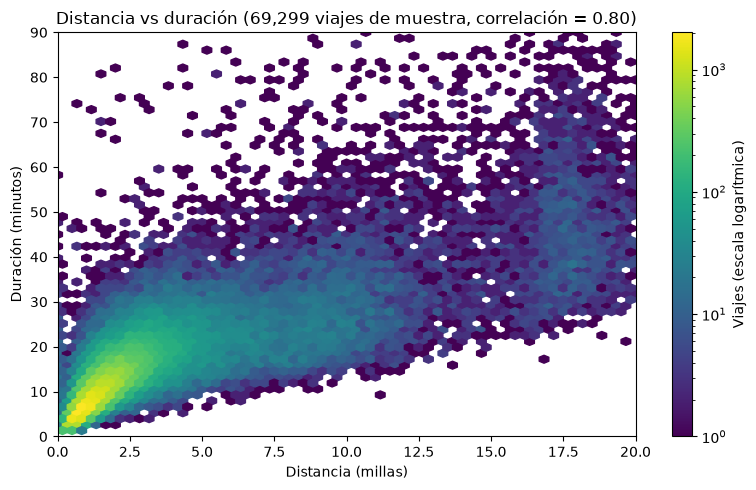

In [7]:
muestra = a_pandas(viajes.sample(0.005, seed=SEED).select("trip_distance", "duracion_min"))
corr = viajes.stat.corr("trip_distance", "duracion_min")
fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(muestra["trip_distance"], muestra["duracion_min"], gridsize=60, extent=(0, 20, 0, 90), bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, label="Viajes (escala logarítmica)")
ax.set(title=f"Distancia vs duración ({len(muestra):,} viajes de muestra, correlación = {corr:.2f})",
       xlabel="Distancia (millas)", ylabel="Duración (minutos)", xlim=(0, 20), ylim=(0, 90))
plt.tight_layout(); plt.show()

Observación: la distancia y la duración tienen una correlación de 0.80, así que la distancia es la variable más útil para predecir. Aun así, para una misma distancia la duración cambia mucho; un viaje de 2.5 millas puede tardar de 5 a más de 30 minutos. Esa diferencia viene del tráfico, la hora y la zona, y por eso el modelo necesita esas variables además de la distancia. También se ve que la mayoría de los viajes son cortos, de menos de 3 millas.

### Viajes por día
Reviso que abril, el mes de prueba, se parezca a los meses de entrenamiento.

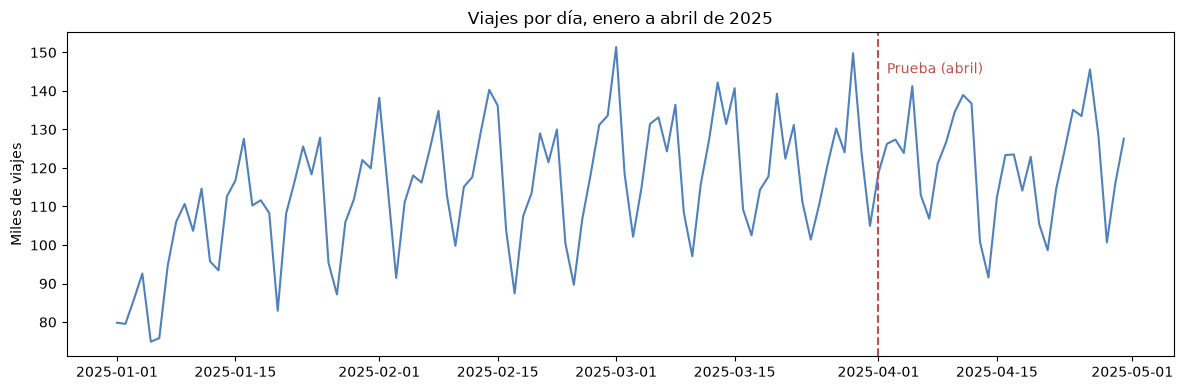

mes
1    103752
2    116920
3    122235
4    121128


In [8]:
import datetime as dt
por_dia = a_pandas(clasificados.where(F.col("motivo_exclusion").isNull())
                   .groupBy(F.to_date("tpep_pickup_datetime").alias("fecha")).count().orderBy("fecha"))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(por_dia["fecha"], por_dia["count"] / 1000, color="#4f81bd")
ax.axvline(dt.date(2025, 4, 1), color="#c0504d", ls="--")
ax.text(dt.date(2025, 4, 2), ax.get_ylim()[1] * 0.95, "Prueba (abril)", color="#c0504d", va="top")
ax.set(title="Viajes por día, enero a abril de 2025", ylabel="Miles de viajes")
plt.tight_layout(); plt.show()
por_dia["mes"] = pd.to_datetime(por_dia["fecha"]).dt.month
print(por_dia.groupby("mes")["count"].mean().round().astype(int).rename("viajes promedio por día").to_string())

Observación: hay un patrón semanal muy marcado, con caídas cada domingo y lunes y picos a mitad y final de semana. La primera semana de enero tuvo menos viajes por las vacaciones. Abril promedia 121 mil viajes por día, casi igual que marzo (122 mil), así que el mes de prueba se parece a los de entrenamiento y la separación por tiempo es justa para el modelo.

### Velocidad y duración por hora
Separa entre semana y fin de semana.

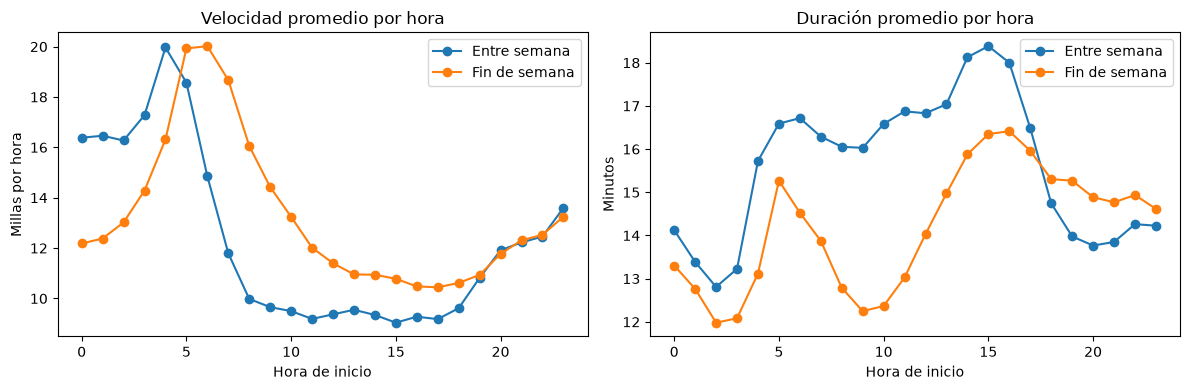

In [9]:
vel = a_pandas(viajes.groupBy("hora", "fin_de_semana")
               .agg(F.avg("velocidad_mph").alias("velocidad"), F.avg("duracion_min").alias("duracion")).orderBy("hora"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for fs, etiqueta in [(0, "Entre semana"), (1, "Fin de semana")]:
    d = vel[vel["fin_de_semana"] == fs]
    ax[0].plot(d["hora"], d["velocidad"], marker="o", label=etiqueta)
    ax[1].plot(d["hora"], d["duracion"], marker="o", label=etiqueta)
ax[0].set(title="Velocidad promedio por hora", xlabel="Hora de inicio", ylabel="Millas por hora")
ax[1].set(title="Duración promedio por hora", xlabel="Hora de inicio", ylabel="Minutos")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

Observación: entre semana los taxis van más rápido a las 4 y 5 am, cerca de 20 millas por hora, y de las 8 am a las 6 pm la velocidad baja a 9 o 10, menos de la mitad. En fin de semana la velocidad alta dura hasta las 7 am y el tráfico de la tarde es más ligero. La duración sigue el mismo patrón: entre semana el pico es a las 3 pm con más de 18 minutos. Esto confirma que la hora y el tipo de día cambian la duración aunque la ruta sea la misma, y por eso los uso como variables.

### Demanda por día y hora

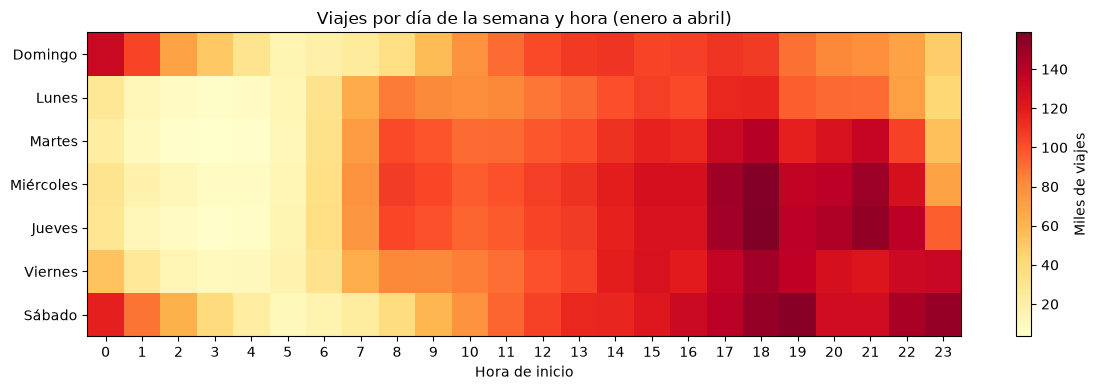

In [10]:
DIAS = {1: "Domingo", 2: "Lunes", 3: "Martes", 4: "Miércoles", 5: "Jueves", 6: "Viernes", 7: "Sábado"}
dem = a_pandas(viajes.groupBy("dia_semana", "hora").count())
tabla_dem = dem.pivot(index="dia_semana", columns="hora", values="count").sort_index() / 1000
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(tabla_dem, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(7), [DIAS[d] for d in tabla_dem.index]); ax.set_xticks(range(24))
ax.set(title="Viajes por día de la semana y hora (enero a abril)", xlabel="Hora de inicio")
fig.colorbar(im, label="Miles de viajes"); plt.tight_layout(); plt.show()

Observación: entre semana la demanda más alta es de 5 pm a 9 pm, con el máximo miércoles y jueves a las 6 pm. El fin de semana hay mucha actividad en la madrugada: sábado y domingo a las 12 am tienen más viajes que cualquier día entre semana a esa hora, por la salida del viernes y sábado en la noche. Lo más bajo es entre las 3 y 5 am de lunes a viernes. Es otro motivo para usar la hora y el día de la semana en el modelo.

### Zonas con más viajes

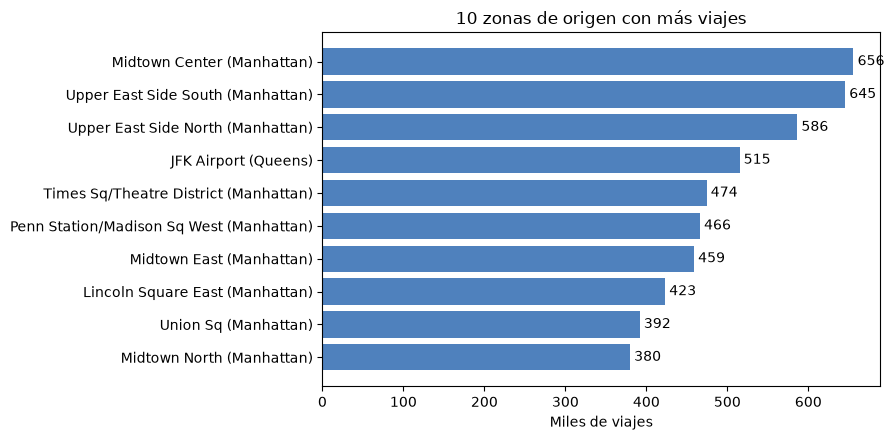

Estas 10 zonas concentran el 35.9% de los viajes (hay 260 zonas de origen).


In [11]:
top = a_pandas(viajes.groupBy("PULocationID").count()
               .join(F.broadcast(zonas.select(F.col("LocationID").alias("PULocationID"), "Zone", "Borough")), "PULocationID")
               .orderBy(F.desc("count")).limit(10)).sort_values("count")
fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.barh(top["Zone"] + " (" + top["Borough"] + ")", top["count"] / 1000, color="#4f81bd")
ax.bar_label(barras, fmt="%.0f", padding=3)
ax.set(title="10 zonas de origen con más viajes", xlabel="Miles de viajes")
plt.tight_layout(); plt.show()
print(f"Estas 10 zonas concentran el {top['count'].sum() / n_viajes:.1%} de los viajes (hay {viajes.select('PULocationID').distinct().count()} zonas de origen).")

Observación: 9 de las 10 zonas con más viajes están en Manhattan y la otra es el aeropuerto JFK. Solo estas 10 zonas, de 260, concentran el 35.9% de los viajes. Como la demanda y la duración dependen tanto del lugar, uso la zona de origen y la de destino como variables. También quiere decir que el modelo tiene muchos más ejemplos de Manhattan que de los otros boroughs, y por eso ahí se equivoca menos.

## Paso 5: Separación y variables
Entreno con enero a marzo y pruebo con abril. Así evalúo al modelo como se usaría en la realidad: con viajes de un periodo que nunca vio.

Solo uso lo que se conoce antes de subir al taxi: zona de origen, zona de destino, hora y día. No uso trip_distance tal cual porque el taxímetro la conoce hasta el final del viaje, y un rodeo por tráfico ya estaría metido en ese dato. Tampoco uso tarifa, propina ni total. En su lugar calculo distancia_ruta: la mediana de la distancia de cada par origen y destino, usando solo los meses de entrenamiento. Si una ruta nunca apareció, uso la mediana de su zona de origen y, si tampoco existe, la mediana general.

In [12]:
train = viajes.where("mes <= 3")
test = viajes.where("mes = 4")

por_ruta = train.groupBy("PULocationID", "DOLocationID").agg(F.percentile_approx("trip_distance", 0.5).alias("dist_ruta"))
por_origen = train.groupBy("PULocationID").agg(F.percentile_approx("trip_distance", 0.5).alias("dist_origen"))
dist_general = train.agg(F.percentile_approx("trip_distance", 0.5)).first()[0]
por_ruta, por_origen = por_ruta.cache(), por_origen.cache()

def agregar_distancia(df):
    return (df.join(F.broadcast(por_ruta), ["PULocationID", "DOLocationID"], "left")
              .join(F.broadcast(por_origen), "PULocationID", "left")
              .withColumn("distancia_ruta", F.coalesce("dist_ruta", "dist_origen", F.lit(dist_general)))
              .drop("dist_ruta", "dist_origen"))

train_f = agregar_distancia(train).persist(StorageLevel.MEMORY_AND_DISK)
test_f = agregar_distancia(test).persist(StorageLevel.MEMORY_AND_DISK)

n_train, n_test = train_f.count(), test_f.count()
assert n_train + n_test == n_viajes, (n_train, n_test, n_viajes)
print(f"Entrenamiento: {n_train:,} | Prueba: {n_test:,} | Rutas distintas: {por_ruta.count():,}")
print(f"Viajes de abril con ruta nunca vista: {test_f.join(por_ruta, ['PULocationID', 'DOLocationID'], 'left_anti').count():,}")

Entrenamiento: 10,279,364 | Prueba: 3,633,834 | Rutas distintas: 42,826


Viajes de abril con ruta nunca vista: 3,423


## Paso 6: Modelos
Comparo tres modelos, de menor a mayor complejidad:

1. Referencia: siempre predice el promedio de entrenamiento. Cualquier modelo útil tiene que ganarle.
2. Regresión lineal con todos los datos de entrenamiento. Las zonas, la hora y el día van con OneHotEncoder.
3. Gradient Boosted Trees (GBT), que puede capturar combinaciones como una ruta específica en hora pico. Las zonas van como variables categóricas y por eso uso maxBins=300, porque hay más de 260 zonas.

In [13]:
idx = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in ["PULocationID", "DOLocationID"]]
LABEL = "duracion_min"

def evaluar(pred, nombre, col_pred="prediction"):
    fila = {"modelo": nombre}
    for m in ["rmse", "mae", "r2"]:
        fila[m] = RegressionEvaluator(labelCol=LABEL, predictionCol=col_pred, metricName=m).evaluate(pred)
    return fila

# Referencia: promedio de entrenamiento
media_train = train_f.agg(F.avg(LABEL)).first()[0]
resultados = [evaluar(test_f.withColumn("prediction", F.lit(float(media_train))), "Referencia (promedio)")]

# Regresión lineal
t0 = time.time()
ohe = OneHotEncoder(inputCols=["PULocationID_idx", "DOLocationID_idx", "hora", "dia_semana"],
                    outputCols=["pu_vec", "do_vec", "hora_vec", "dia_vec"])
ensamble_lr = VectorAssembler(inputCols=["pu_vec", "do_vec", "hora_vec", "dia_vec", "distancia_ruta"], outputCol="features")
lr = LinearRegression(labelCol=LABEL, featuresCol="features", regParam=0.01)
modelo_lr = Pipeline(stages=idx + [ohe, ensamble_lr, lr]).fit(train_f)
tiempo_lr = time.time() - t0
resultados.append(evaluar(modelo_lr.transform(test_f), "Regresión lineal"))
print(f"Regresión lineal entrenada con {n_train:,} viajes en {tiempo_lr:.0f} s")
pd.DataFrame(resultados).round(3)

Regresión lineal entrenada con 10,279,364 viajes en 9 s


,modelo,rmse,mae,r2
0,Referencia (promedio),12.786,8.556,-0.008
1,Regresión lineal,6.967,4.582,0.701


### Búsqueda de hiperparámetros
Con TrainValidationSplit pruebo 4 combinaciones de maxDepth y stepSize. Usé TrainValidationSplit en lugar de CrossValidator porque evalúa cada combinación una sola vez, y con estos volúmenes eso ahorra mucho cómputo. La búsqueda corre sobre una muestra aleatoria del entrenamiento; con millones de filas una muestra alcanza para comparar combinaciones.

In [14]:
ensamble_gbt = VectorAssembler(inputCols=["PULocationID_idx", "DOLocationID_idx", "hora", "dia_semana", "fin_de_semana", "distancia_ruta"],
                               outputCol="features")
gbt = GBTRegressor(labelCol=LABEL, featuresCol="features", maxIter=30, maxBins=300, seed=SEED, maxMemoryInMB=1024, cacheNodeIds=True)
pipeline_gbt = Pipeline(stages=idx + [ensamble_gbt, gbt])

grid = ParamGridBuilder().addGrid(gbt.maxDepth, [5, 8]).addGrid(gbt.stepSize, [0.1, 0.2]).build()
tvs = TrainValidationSplit(estimator=pipeline_gbt, estimatorParamMaps=grid,
                           evaluator=RegressionEvaluator(labelCol=LABEL, metricName="rmse"),
                           trainRatio=0.8, parallelism=2, seed=SEED)
muestra_tuning = train_f.sample(FRACCION_TUNING, seed=SEED).cache()
t0 = time.time()
modelo_tvs = tvs.fit(muestra_tuning)
print(f"Búsqueda con {muestra_tuning.count():,} viajes en {time.time() - t0:.0f} s")

for params, rmse in sorted(zip(grid, modelo_tvs.validationMetrics), key=lambda x: x[1]):
    print({k.name: v for k, v in params.items()}, f"RMSE validación: {rmse:.3f}")
mejor = min(zip(grid, modelo_tvs.validationMetrics), key=lambda x: x[1])[0]
mejor_depth, mejor_step = mejor[gbt.maxDepth], mejor[gbt.stepSize]
_ = muestra_tuning.unpersist()

Búsqueda con 513,957 viajes en 441 s
{'maxDepth': 5, 'stepSize': 0.2} RMSE validación: 5.687
{'maxDepth': 5, 'stepSize': 0.1} RMSE validación: 5.694
{'maxDepth': 8, 'stepSize': 0.1} RMSE validación: 6.276
{'maxDepth': 8, 'stepSize': 0.2} RMSE validación: 6.443


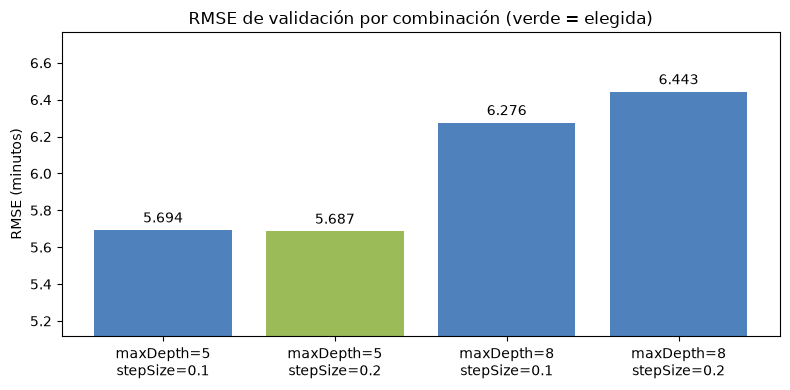

In [15]:
etiquetas = [f"maxDepth={p[gbt.maxDepth]}\nstepSize={p[gbt.stepSize]}" for p in grid]
colores = ["#9bbb59" if (p[gbt.maxDepth], p[gbt.stepSize]) == (mejor_depth, mejor_step) else "#4f81bd" for p in grid]
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(etiquetas, modelo_tvs.validationMetrics, color=colores)
ax.bar_label(barras, fmt="%.3f", padding=3)
ax.set(title="RMSE de validación por combinación (verde = elegida)", ylabel="RMSE (minutos)",
       ylim=(min(modelo_tvs.validationMetrics) * 0.9, max(modelo_tvs.validationMetrics) * 1.05))
plt.tight_layout(); plt.show()

Observación: los árboles de profundidad 5 le ganaron a los de profundidad 8 con las dos tasas de aprendizaje. Con una muestra de 514 mil viajes, los árboles más profundos se sobreajustan: aprenden detalles de la muestra que no se repiten en validación. Entre stepSize 0.1 y 0.2 casi no hay diferencia (5.694 contra 5.687), así que me quedé con 0.2.

### Modelo final

In [16]:
datos_gbt = train_f if FRACCION_GBT >= 1 else train_f.sample(FRACCION_GBT, seed=SEED)
datos_gbt = datos_gbt.persist(StorageLevel.MEMORY_AND_DISK)
n_gbt = datos_gbt.count()
t0 = time.time()
modelo = pipeline_gbt.fit(datos_gbt, {gbt.maxDepth: mejor_depth, gbt.stepSize: mejor_step})
tiempo_gbt = time.time() - t0
print(f"GBT (maxDepth={mejor_depth}, stepSize={mejor_step}) entrenado con {n_gbt:,} viajes en {tiempo_gbt / 60:.1f} min")
_ = datos_gbt.unpersist()

GBT (maxDepth=5, stepSize=0.2) entrenado con 10,279,364 viajes en 7.8 min


## Paso 7: Evaluación
Evalúo todo con los viajes de abril, que ningún modelo vio. RMSE y MAE están en minutos: MAE es el error promedio y RMSE castiga más los errores grandes. R2 indica qué parte de la variación de la duración explica el modelo.

In [17]:
pred_test = modelo.transform(test_f).select("PULocationID", "DOLocationID", "hora", "dia_semana", "distancia_ruta", LABEL, "prediction", "features") \
                  .persist(StorageLevel.MEMORY_AND_DISK)
resultados.append(evaluar(pred_test, "GBT"))
tabla_resultados = pd.DataFrame(resultados).round(3)
tabla_resultados

,modelo,rmse,mae,r2
0,Referencia (promedio),12.786,8.556,-0.008
1,Regresión lineal,6.967,4.582,0.701
2,GBT,5.876,3.721,0.787


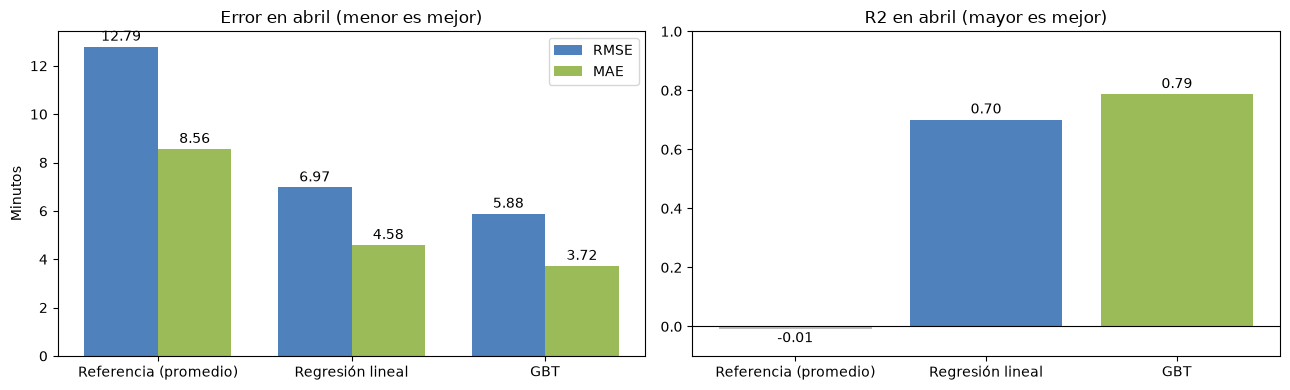

In [18]:
t = tabla_resultados
x = range(len(t)); w = 0.38
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for desfase, metrica, color in [(-w / 2, "rmse", "#4f81bd"), (w / 2, "mae", "#9bbb59")]:
    barras = ax[0].bar([i + desfase for i in x], t[metrica], w, label=metrica.upper(), color=color)
    ax[0].bar_label(barras, fmt="%.2f", padding=2)
ax[0].set_xticks(list(x), t["modelo"]); ax[0].legend()
ax[0].set(title="Error en abril (menor es mejor)", ylabel="Minutos")
barras = ax[1].bar(t["modelo"], t["r2"], color=["#bfbfbf", "#4f81bd", "#9bbb59"])
ax[1].bar_label(barras, fmt="%.2f", padding=2); ax[1].axhline(0, color="black", lw=0.8)
ax[1].set(title="R2 en abril (mayor es mejor)", ylim=(-0.1, 1))
plt.tight_layout(); plt.show()

Observación: los dos modelos le ganan por mucho a la referencia, que tiene un R2 de casi cero porque siempre predice lo mismo. La regresión lineal ya explica el 70% de la variación, y el GBT sube a 79% y baja el error promedio de 4.58 a 3.72 minutos. La mejora del GBT viene de que puede combinar variables, por ejemplo una ruta específica en hora pico, algo que la regresión lineal no puede hacer porque suma cada efecto por separado.

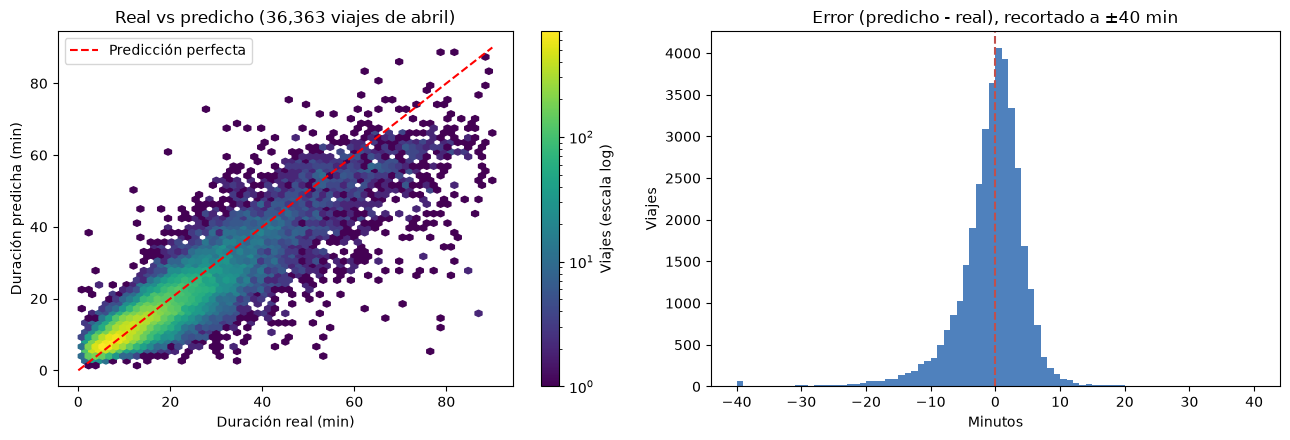

Viajes de abril con error de ±2 min: 40.3% | ±5 min: 77.6% | ±10 min: 94.1%
El modelo predice de menos en el 49.1% de los viajes


In [19]:
error = F.col("prediction") - F.col(LABEL)
dentro = pred_test.agg(*[F.avg((F.abs(error) <= m).cast("int")).alias(f"m{m}") for m in (2, 5, 10)],
                       F.avg((error < 0).cast("int")).alias("subestima")).first()
m = a_pandas(pred_test.sample(0.01, seed=SEED).select(LABEL, "prediction"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
hb = ax[0].hexbin(m[LABEL], m["prediction"], gridsize=60, extent=(0, 90, 0, 90), bins="log", cmap="viridis", mincnt=1)
ax[0].plot([0, 90], [0, 90], "r--", label="Predicción perfecta"); ax[0].legend(loc="upper left")
fig.colorbar(hb, ax=ax[0], label="Viajes (escala log)")
ax[0].set(title=f"Real vs predicho ({len(m):,} viajes de abril)", xlabel="Duración real (min)", ylabel="Duración predicha (min)")
ax[1].hist((m["prediction"] - m[LABEL]).clip(-40, 40), bins=80, color="#4f81bd")
ax[1].axvline(0, color="#c0504d", ls="--")
ax[1].set(title="Error (predicho - real), recortado a ±40 min", xlabel="Minutos", ylabel="Viajes")
plt.tight_layout(); plt.show()
print(f"Viajes de abril con error de ±2 min: {dentro.m2:.1%} | ±5 min: {dentro.m5:.1%} | ±10 min: {dentro.m10:.1%}")
print(f"El modelo predice de menos en el {dentro.subestima:.1%} de los viajes")

Observación: la mayoría de los puntos queda cerca de la diagonal, sobre todo en los viajes cortos, que son los más comunes. En los viajes de más de 50 minutos los puntos quedan debajo de la línea: el modelo los predice más cortos de lo que fueron, porque normalmente se deben a tráfico o incidentes que el modelo no conoce. Por eso la cola izquierda del histograma es más larga. Aun así, el error está centrado en cero y el modelo predice de menos en 49.1% de los viajes, así que no tiene un sesgo general. El 77.6% de los viajes de abril queda dentro de ±5 minutos y el 94.1% dentro de ±10.

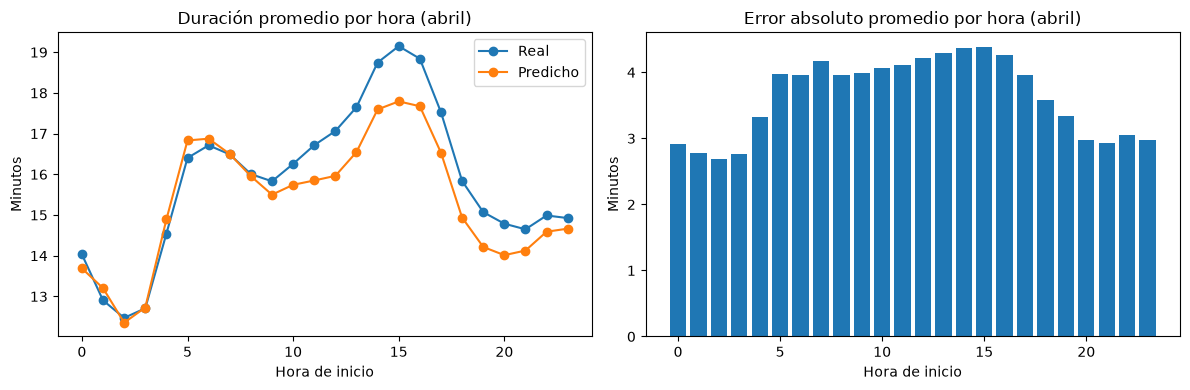

distancia_ruta       0.6066
DOLocationID_idx     0.1373
PULocationID_idx     0.1050
hora                 0.1037
dia_semana           0.0262
fin_de_semana        0.0211


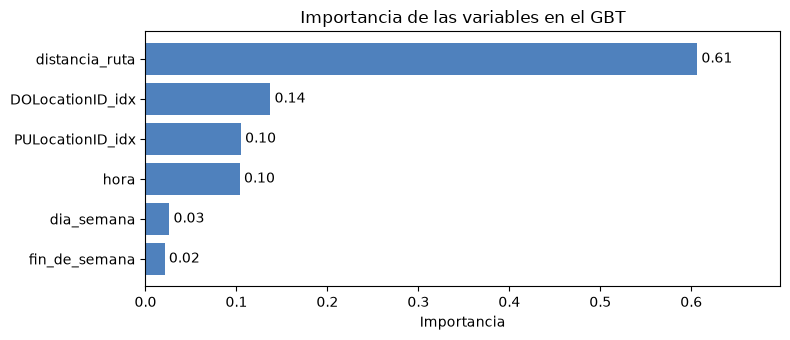

In [20]:
# Error por hora de inicio
error_col = F.col("prediction") - F.col(LABEL)
por_hora = pred_test.groupBy("hora").agg(F.count("*").alias("viajes"), F.avg(F.abs(error_col)).alias("mae"),
                                         F.avg(LABEL).alias("real"), F.avg("prediction").alias("predicho")).orderBy("hora").collect()
horas = [r.hora for r in por_hora]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(horas, [r.real for r in por_hora], marker="o", label="Real")
ax[0].plot(horas, [r.predicho for r in por_hora], marker="o", label="Predicho")
ax[0].set(title="Duración promedio por hora (abril)", xlabel="Hora de inicio", ylabel="Minutos"); ax[0].legend()
ax[1].bar(horas, [r.mae for r in por_hora])
ax[1].set(title="Error absoluto promedio por hora (abril)", xlabel="Hora de inicio", ylabel="Minutos")
plt.tight_layout(); plt.show()

# Importancia de las variables
atributos = pred_test.schema["features"].metadata["ml_attr"]["attrs"]
nombres = {a["idx"]: a["name"] for grupo in atributos.values() for a in grupo}
importancias = sorted(((nombres[i], float(v)) for i, v in enumerate(modelo.stages[-1].featureImportances.toArray())), key=lambda x: x[1], reverse=True)
for nombre, valor in importancias:
    print(f"{nombre:<20} {valor:.4f}")

nombres_imp, valores_imp = zip(*importancias[::-1])
fig, ax = plt.subplots(figsize=(8, 3.5))
barras = ax.barh(nombres_imp, valores_imp, color="#4f81bd")
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set(title="Importancia de las variables en el GBT", xlabel="Importancia", xlim=(0, max(valores_imp) * 1.15))
plt.tight_layout(); plt.show()

Observación: el modelo sigue bien la forma de la duración durante el día, pero de las 10 am a las 6 pm se queda un poco abajo de lo real, y en esas horas el error promedio pasa de 4 minutos. En la madrugada el error es de menos de 3 minutos porque hay poco tráfico y los viajes son más predecibles. En la importancia, distancia_ruta pesa 0.61, más que todas las demás juntas, lo que coincide con la correlación de 0.80 del análisis exploratorio. Le siguen las zonas de destino y origen y la hora; el día de la semana y el fin de semana aportan poco porque la hora ya captura buena parte de ese efecto.

## Paso 8: Predicciones
Primero comparo 10 viajes reales de abril contra su predicción. Después pruebo viajes que armé a mano, para ver si el modelo reacciona a la hora y al día.

In [21]:
nombres_zona = zonas.select(F.col("LocationID"), F.col("Zone"))
origen = nombres_zona.withColumnRenamed("LocationID", "PULocationID").withColumnRenamed("Zone", "origen")
destino = nombres_zona.withColumnRenamed("LocationID", "DOLocationID").withColumnRenamed("Zone", "destino")

pred_test.sample(0.00001, seed=SEED).limit(10).join(origen, "PULocationID").join(destino, "DOLocationID") \
    .select("origen", "destino", "hora", F.round(LABEL, 1).alias("real_min"), F.round("prediction", 1).alias("predicho_min")).show(truncate=False)

+-----------------------------+-----------------------------+----+--------+------------+
|origen                       |destino                      |hora|real_min|predicho_min|
+-----------------------------+-----------------------------+----+--------+------------+
|Gramercy                     |Lincoln Square East          |8   |28.0    |24.9        |
|JFK Airport                  |Times Sq/Theatre District    |18  |57.3    |57.0        |
|LaGuardia Airport            |Lenox Hill West              |14  |43.3    |29.9        |
|LaGuardia Airport            |Times Sq/Theatre District    |9   |45.2    |36.1        |
|Midtown Center               |Upper East Side South        |12  |24.9    |10.3        |
|Penn Station/Madison Sq West |Murray Hill                  |20  |8.3     |8.2         |
|Sutton Place/Turtle Bay North|Sutton Place/Turtle Bay North|16  |6.9     |6.9         |
|Times Sq/Theatre District    |Midtown East                 |23  |11.6    |7.4         |
|Times Sq/Theatre Dis

In [22]:
casos = [("JFK Airport", "Times Sq/Theatre District", 8, 2), ("JFK Airport", "Times Sq/Theatre District", 3, 1),
         ("JFK Airport", "Times Sq/Theatre District", 17, 5), ("Upper East Side South", "Midtown Center", 17, 4),
         ("Upper East Side South", "Midtown Center", 4, 1), ("LaGuardia Airport", "Financial District North", 8, 3)]
ids = {r.Zone: r.LocationID for r in zonas.collect()}
nuevos = spark.createDataFrame([(ids[o], ids[d], h, dia, int(dia in (1, 7)), o, d) for o, d, h, dia in casos],
                               ["PULocationID", "DOLocationID", "hora", "dia_semana", "fin_de_semana", "origen", "destino"])
DIAS = {1: "Domingo", 2: "Lunes", 3: "Martes", 4: "Miércoles", 5: "Jueves", 6: "Viernes", 7: "Sábado"}
mapa_dias = F.create_map(*[F.lit(x) for par in DIAS.items() for x in par])
modelo.transform(agregar_distancia(nuevos)).select("origen", "destino", mapa_dias[F.col("dia_semana")].alias("dia"), "hora",
    F.round("distancia_ruta", 2).alias("millas"), F.round("prediction", 1).alias("predicho_min")).show(truncate=False)

+---------------------+-------------------------+---------+----+------+------------+
|origen               |destino                  |dia      |hora|millas|predicho_min|
+---------------------+-------------------------+---------+----+------+------------+
|JFK Airport          |Times Sq/Theatre District|Lunes    |8   |17.7  |61.0        |
|JFK Airport          |Times Sq/Theatre District|Domingo  |3   |17.7  |29.7        |
|JFK Airport          |Times Sq/Theatre District|Jueves   |17  |17.7  |62.4        |
|Upper East Side South|Midtown Center           |Miércoles|17  |1.0   |10.4        |
|Upper East Side South|Midtown Center           |Domingo  |4   |1.0   |6.8         |
|LaGuardia Airport    |Financial District North |Martes   |8   |12.5  |39.2        |
+---------------------+-------------------------+---------+----+------+------------+



Observación: en los viajes reales de abril, la mayoría de las predicciones queda a pocos minutos de lo real, sobre todo dentro de Manhattan. Los errores más grandes son viajes desde LaGuardia o con tráfico fuera de lo normal; por ejemplo, de Midtown Center a Upper East Side South el viaje duró 24.9 minutos y el modelo esperaba 10.3. En los viajes que armé a mano, el modelo sí reacciona a la hora y al día: de JFK a Times Square predice 29.7 minutos un domingo a las 3 am y más de 60 en hora pico entre semana, con la misma distancia. Lo mismo pasa con un viaje corto dentro de Manhattan: 6.8 minutos de madrugada contra 10.4 a las 5 pm.

## Paso 9: Guardar el modelo
Guardo el pipeline completo y la tabla de distancias por ruta, y compruebo que el modelo recargado da el mismo resultado.

In [23]:
modelo.write().overwrite().save(MODELO_DIR)
por_ruta.write.mode("overwrite").parquet(RUTAS_DIR)
recargado = PipelineModel.load(MODELO_DIR)
rmse_recargado = RegressionEvaluator(labelCol=LABEL, metricName="rmse").evaluate(recargado.transform(test_f))
assert abs(rmse_recargado - resultados[-1]["rmse"]) < 1e-6
print(f"Modelo recargado correctamente. RMSE: {rmse_recargado:.3f}")

Modelo recargado correctamente. RMSE: 5.876


## Paso 10: Datos para el tablero
Tableau no necesita los millones de filas: Spark agrega los viajes limpios en tablas chicas y las exporto a CSV. Reviso que las tablas cuadren con el total de viajes limpios.

In [24]:
TABLERO_DIR.mkdir(parents=True, exist_ok=True)
def exportar(df, nombre):
    tabla = pd.DataFrame([r.asDict() for r in df.collect()])
    tabla.to_csv(TABLERO_DIR / f"{nombre}.csv", index=False)
    print(f"{nombre}.csv: {len(tabla):,} filas")
    return tabla

MESES_ES = {1: "Enero", 2: "Febrero", 3: "Marzo", 4: "Abril"}
mapa_meses = F.create_map(*[F.lit(x) for par in MESES_ES.items() for x in par])
zona_pu = zonas.select(F.col("LocationID").alias("PULocationID"), F.col("Borough").alias("borough_origen"), F.col("Zone").alias("zona_origen"))
zona_do = zonas.select(F.col("LocationID").alias("DOLocationID"), F.col("Borough").alias("borough_destino"), F.col("Zone").alias("zona_destino"))
metricas = [F.count("*").alias("viajes"), F.round(F.avg("duracion_min"), 2).alias("duracion_prom_min"),
            F.round(F.avg("trip_distance"), 2).alias("distancia_prom_millas"), F.round(F.avg("velocidad_mph"), 2).alias("velocidad_prom_mph"),
            F.round(F.sum("total_amount"), 2).alias("ingreso_total")]

demanda = exportar(viajes.join(F.broadcast(zona_pu), "PULocationID")
    .withColumn("mes_nombre", mapa_meses[F.col("mes")]).withColumn("dia", mapa_dias[F.col("dia_semana")])
    .groupBy("mes", "mes_nombre", "dia_semana", "dia", "hora", "borough_origen").agg(*metricas), "demanda_hora_dia")

zonas_t = exportar(viajes.join(F.broadcast(zona_pu), "PULocationID")
    .groupBy("PULocationID", "borough_origen", "zona_origen").agg(*metricas), "zonas_origen")

rutas = exportar(viajes.join(F.broadcast(zona_pu), "PULocationID").join(F.broadcast(zona_do), "DOLocationID")
    .groupBy("zona_origen", "borough_origen", "zona_destino", "borough_destino").agg(*metricas)
    .orderBy(F.desc("viajes")).limit(200), "rutas_top")

errores = exportar(pred_test.join(F.broadcast(zona_pu), "PULocationID").withColumn("dia", mapa_dias[F.col("dia_semana")])
    .groupBy("dia_semana", "dia", "hora", "borough_origen")
    .agg(F.count("*").alias("viajes"), F.round(F.avg(LABEL), 2).alias("real_prom_min"), F.round(F.avg("prediction"), 2).alias("predicho_prom_min"),
         F.round(F.avg(F.abs(error_col)), 2).alias("mae_min")), "error_modelo")

assert demanda["viajes"].sum() == n_viajes and zonas_t["viajes"].sum() == n_viajes
assert errores["viajes"].sum() == n_test
print("Las tablas cuadran con los viajes limpios.")

demanda_hora_dia.csv: 3,182 filas


zonas_origen.csv: 260 filas


rutas_top.csv: 200 filas


error_modelo.csv: 796 filas
Las tablas cuadran con los viajes limpios.


## Paso 11: Tablero en Tableau Public
Enlace público: https://public.tableau.com/app/profile/carlos.martinez2098/viz/MartinezVazquez_Carlos_Taxi_Tableau/TaxisamarillosdeNYCdemandayduracineneroaabrilde2025

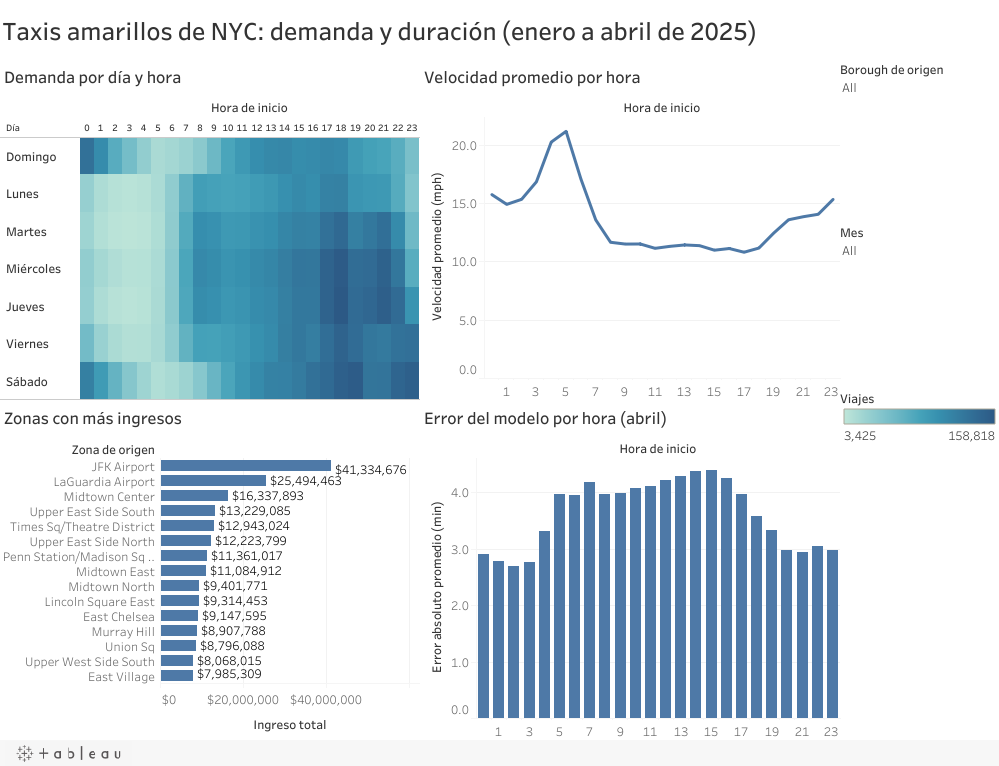

Armé el tablero en Tableau Public con las tablas del Paso 10. Cada gráfica apoya una decison:

- Demanda por día y hora: cuándo poner más taxis. El pico es jueves a las 6 pm y lo más bajo es martes a las 3 am. Los filtros de borough y mes aplican a esta gráfica.
- Velocidad promedio por hora: cuándo hay más congestión. Baja de 21.2 millas por hora a las 5 am a 10.8 a las 5 pm.
- Zonas con más ingresos: dónde colocar los taxis. Estas 15 zonas generan el 54.4% de los ingresos.
- Error del modelo por hora: cuándo confiar menos en la estimación. Va de 2.7 minutos a las 2 am a 4.4 a las 3 pm.

## Paso 12: Conclusiones

Limpié 15.2 millones de viajes y me quedé con 13.9 millones (91.7%). Probé los modelos con los viajes de abril, que no usé para entrenar:

| Modelo | RMSE (min) | MAE (min) | R2 |
|---|---|---|---|
| Referencia (promedio) | 12.79 | 8.56 | -0.01 |
| Regresión lineal | 6.97 | 4.58 | 0.70 |
| GBT | 5.88 | 3.72 | 0.79 |

El mejor fue el GBT: se equivoca por 3.72 minutos en promedio, menos de la mitad que la referencia. La variable más importante fue la distancia típica de la ruta (0.61). El modelo también reacciona a la hora: de JFK a Times Square predice unos 30 minutos un domingo a las 3 am y unos 61 un lunes a las 8 am.

Su punto débil son los viajes fuera de Manhattan, donde el error sube de 3.3 minutos a entre 6 y 8 en Queens, Brooklyn y el Bronx. También falla más en la tarde, y no sabe de clima, accidentes ni eventos. Para mejorarlo agregaría clima y más meses de datos, y volvería a probar árboles más profundos con una muestra más grande.

In [25]:
spark.stop()